# Compute Distances to Resected area

## Imports

In [175]:
import mindmap as mm 
import mne
from pathlib import Path
import nibabel as nib
import numpy as np
import pyvista as pv

config = mm.io.read_config("../configurations/spike.yml")
mm_dir = Path(config["MM_DIR"])

## Data

In [196]:
sub = "sub-pat02"

# files
sources = mm_dir/sub/"src"/f"{sub}_ddm-surf-7-src.fif"
cset    = mm_dir/sub/"stc"/f"{sub}_cset2-0.01"
sloreta = mm_dir/sub/"stc"/f"{sub}_sloreta-0.01"
resec1  = mm_dir/sub/"resec"/f"{sub}_man-recon-seg.nii.gz"
resec2  = mm_dir/sub/"resec"/f"{sub}_auto-seg.nii.gz"

# load
sources = mne.read_source_spaces(sources)
cset    = mne.read_source_estimate(cset)
sloreta = mne.read_source_estimate(sloreta)

if resec1.exists() == True:
    resection = nib.load(resec1)
elif resec2.exists() == True:
    resection = nib.load(resec2)
else:
    resection = None
    print(f"\033[93mNo resection found for subject {sub}'\033[0m")

    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    2 source spaces read
No resection found for subject sub-pat02'


In [200]:
mm.viz.plot_brain_time_series(sources, np.abs(sloreta.data), cmap="Reds")

Widget(value='<iframe src="http://localhost:41935/index.html?ui=P_0x7f08b4560d70_93&reconnect=auto" class="pyv…

## Utilities

In [194]:
def measure_distance(target_point, target_area, x=100):
    distances = target_area-target_point

    if x == "all":
        mean_distance = np.mean(distances, axis=0)
        norm          = np.linalg.norm(mean_distance)

    else:
        norms         = np.linalg.norm(distances, ord=2, axis=1)
        nearest       = distances[np.argsort(norms)[:x],:]
        mean_distance = np.mean(nearest, axis=0)
        norm          = np.linalg.norm(mean_distance)

    return norm

def select_source_estimate(stc, sources):
    idx, tp = np.unravel_index(np.argmax(stc.data), stc.data.shape)
    signal  = stc.data[:, tp]
    se      = mm.utils.get_src_position(sources)[idx]

    return se, signal

## Visualize

In [195]:
# source estimate
se, signal = select_source_estimate(sloreta, sources)

# cloud point of resected area
hole = np.argwhere(resection.get_fdata()>0)
hole = mne.transforms.apply_trans(resection.affine, hole)/1000

# distance
dist = measure_distance(se, hole, x=10)
print(f"Distance Error: {dist*1000:.1f}mm")

# plot
plotter = mm.viz.plot_brain_signal(sources, np.abs(signal), cmap="Reds")
plotter.add_mesh(pv.PolyData(hole), style="points_gaussian", point_size=10, emissive=True, color="purple", label="Resected Area")
plotter.add_mesh(pv.PolyData(se), render_points_as_spheres=True, point_size=20, color="green", label="Source Estimation")
plotter.add_legend(face="circle")
plotter.show()

Distance Error: 38.6mm


Widget(value='<iframe src="http://localhost:41935/index.html?ui=P_0x7f093a568e60_80&reconnect=auto" class="pyv…

## Create Distance Plot

In [180]:
# imports
import numpy as np

subjects = [
    "sub-pat03", "sub-pat06", "sub-pat08", "sub-pat09", "sub-pat10", "sub-pat11", "sub-pat12", 
    "sub-pat13", "sub-pat15", "sub-pat16", "sub-pat17", "sub-pat20", "sub-pat21", "sub-pat22", 
    "sub-pat23", "sub-pat24", "sub-pat25", "sub-pat26", "sub-pat27",
]

src_file     = lambda s: mm_dir/sub/"src"/f"{s}_ddm-surf-7-src.fif"
cset_file    = lambda s: mm_dir/sub/"stc"/f"{s}_cset2-0.01"
sloreta_file = lambda s: mm_dir/sub/"stc"/f"{s}_sloreta-0.01"
resec1_file  = lambda s: mm_dir/sub/"resec"/f"{s}_man-recon-seg.nii.gz"
resec2_file  = lambda s: mm_dir/sub/"resec"/f"{s}_auto-seg.nii.gz"

distances = np.inf*np.ones((len(subjects),2))
for i,sub in enumerate(subjects):
    sources = mne.read_source_spaces(src_file(sub), verbose="error")
    cset    = mne.read_source_estimate(cset_file(sub))
    sloreta = mne.read_source_estimate(sloreta_file(sub))
    
    resec1 = resec1_file(sub)
    resec2 = resec2_file(sub)
    if resec1.exists() == True:
        resection = nib.load(resec1)
    elif resec2.exists() == True:
        resection = nib.load(resec2)
    else:
        resection = None
        print(f"\033[93mNo resection found for subject {sub}'\033[0m")
        continue

    half = int(cset.data.shape[1]/2)
    cset.data = cset.data[:,half-5:half+5]
    sloreta.data = sloreta.data[:,half-5:half+5]

    # Handle Exceptions
    if sub=="sub-pat15":
        # crop time around peak
        pass
    if sub=="sub-pat21":
        #crop time around peak
        pass

    cset_se, _    = select_source_estimate(cset, sources)
    sloreta_se, _ = select_source_estimate(sloreta, sources)

    # cloud point of resected area
    hole = np.argwhere(resection.get_fdata()>0)
    hole = mne.transforms.apply_trans(resection.affine, hole)/1000

    # distance
    distances[i,0] = measure_distance(cset_se, hole, x=10)
    distances[i,1] = measure_distance(sloreta_se, hole, x=10)

# x position for scatter plot
xs = np.random.normal(0, 0.04, (distances.shape[0],2))
xs[:,0] += 1
xs[:,1] += 2

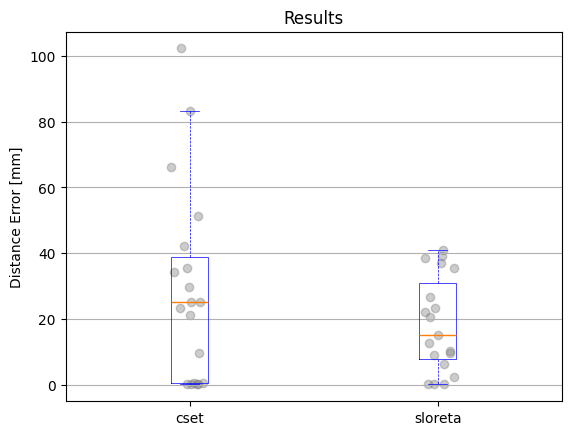

In [184]:
from matplotlib import cm 
import matplotlib.pyplot as plt

colors = "gray"
#colors = [cm.prism(0.), cm.prism(0.), cm.prism(0.), cm.prism(0.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.)]
#colors = [cm.prism(1.), cm.prism(0.5), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(0.), cm.prism(0.5), cm.prism(0.), cm.prism(1.), cm.prism(0.5), cm.prism(1.), cm.prism(1.), cm.prism(1.), cm.prism(0.5), cm.prism(1.), cm.prism(1.), cm.prism(0.)]

plt.boxplot(
    distances*1000, 
    tick_labels=["cset", "sloreta"],
    whiskerprops={"color":"blue", "linewidth":0.5, "linestyle":"--"},
    boxprops={"color":"blue", "linewidth":0.5},
    capprops={"color":"blue", "linewidth":0.5},
    showfliers=False,
)

for x, dist, clevel in zip(xs.T, distances.T, [1., 0.5]):
    plt.scatter(x, dist*1000, color=colors, alpha=0.4)

plt.title("Results")
plt.ylabel("Distance Error [mm]")
plt.grid(which="major", axis="y")
plt.show()